# Dimensionality Reduction, Clustering & Tree-Based Ensemble Models
**Project:** Website Bot & Network Intrusion Detection  
**Dataset:** Standardized UNSW-NB15 (`Cleaned_DS/`)  
**Scope:**
1. **Dimensionality Reduction:** Principal Component Analysis (PCA) with explained variance analysis and 2D flow projection.
2. **Unsupervised Clustering:** K-Means clustering, Elbow method optimization, and silhouette cluster evaluation.
3. **Tree-Based Models:** Decision Tree classification comparing Gini Index vs. Entropy criteria, with depth regularization.
4. **Ensemble Modeling:** Random Forest classifier with feature importance extraction.
5. **Cross-Review Performance Synthesis:** Benchmark comparison between Review II linear baselines and Review III non-linear models.


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 1. Data Ingestion
We load the partitioned, standardized datasets from `Cleaned_DS/`:
* `train_cleaned.csv`: 206,138 records (80%)
* `test_cleaned.csv`: 51,535 records (20%)


In [2]:
clean_dir = "Cleaned_DS"
train_df = pd.read_csv(os.path.join(clean_dir, "train_cleaned.csv"))
test_df = pd.read_csv(os.path.join(clean_dir, "test_cleaned.csv"))

X_train = train_df.drop(columns=['label', 'attack_cat'])
y_train = train_df['label'].values
attack_train = train_df['attack_cat'].values

X_test = test_df.drop(columns=['label', 'attack_cat'])
y_test = test_df['label'].values
attack_test = test_df['attack_cat'].values

print(f"Train samples: {X_train.shape[0]:,}, Features: {X_train.shape[1]}")
print(f"Test samples:  {X_test.shape[0]:,}, Features: {X_test.shape[1]}")


Train samples: 206,138, Features: 61
Test samples:  51,535, Features: 61


## 2. Dimensionality Reduction: Principal Component Analysis (PCA)
With 61 features, many network metrics exhibit strong collinearity. PCA projects the feature space onto orthogonal axes that maximize variance, mitigating multicollinearity and enabling 2D visualization of the decision space.


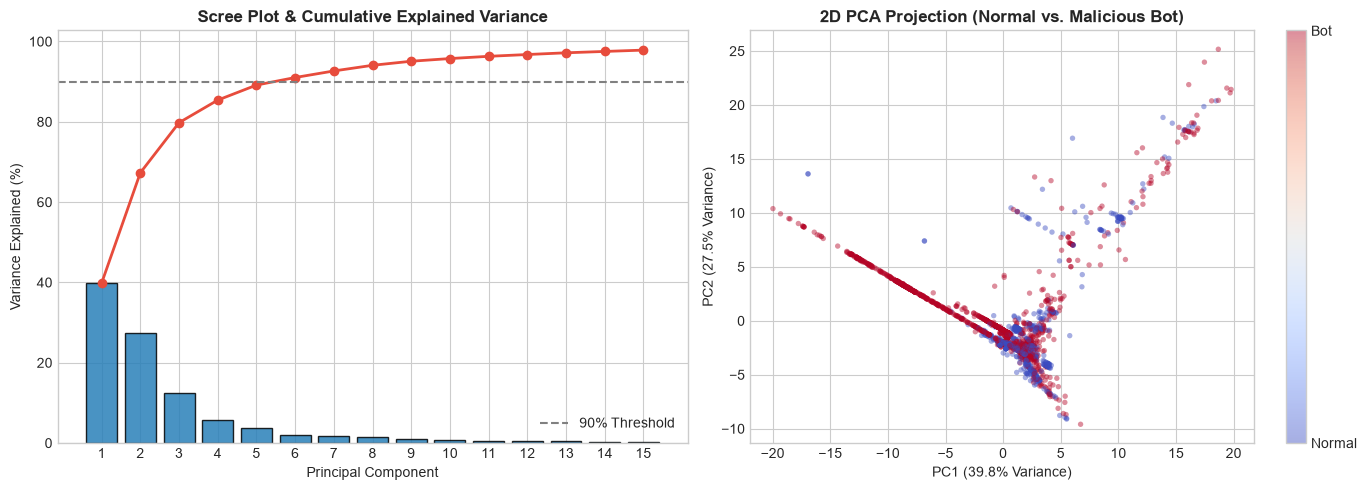

Top 2 PCs capture 67.31% of total dataset variance.


In [3]:
pca_full = PCA(n_components=15, random_state=RANDOM_STATE)
pca_full.fit(X_train)

exp_var = pca_full.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].bar(range(1, 16), exp_var * 100, color='#2980b9', edgecolor='black', alpha=0.85)
axes[0].plot(range(1, 16), cum_var * 100, color='#e74c3c', marker='o', lw=2)
axes[0].set_title('Scree Plot & Cumulative Explained Variance', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance Explained (%)')
axes[0].set_xticks(range(1, 16))
axes[0].axhline(y=90, color='gray', linestyle='--', label='90% Threshold')
axes[0].legend(loc='lower right')

# 2D Projection
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca2 = pca_2d.fit_transform(X_train)

sample_idx = np.random.choice(len(X_train), size=2000, replace=False)
scatter = axes[1].scatter(
    X_train_pca2[sample_idx, 0], X_train_pca2[sample_idx, 1],
    c=y_train[sample_idx], cmap='coolwarm', alpha=0.45, s=15, edgecolors='none'
)
axes[1].set_title('2D PCA Projection (Normal vs. Malicious Bot)', fontsize=12, fontweight='bold')
axes[1].set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% Variance)')
axes[1].set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% Variance)')
cbar = plt.colorbar(scatter, ax=axes[1], ticks=[0, 1])
cbar.ax.set_yticklabels(['Normal', 'Bot'])

plt.tight_layout()
os.makedirs('output_figures', exist_ok=True)
plt.savefig('output_figures/dr_01_pca_scree_and_2d_projection.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Top 2 PCs capture {cum_var[1]*100:.2f}% of total dataset variance.")


## 3. Unsupervised Clustering & Evaluation (K-Means)
To evaluate whether bot traffic can be discovered without supervision, we apply K-Means clustering.
1. **Elbow Method:** Evaluates inertia across cluster counts $K \in [2, 7]$.
2. **Silhouette Analysis:** Quantifies cluster cohesion and separation.


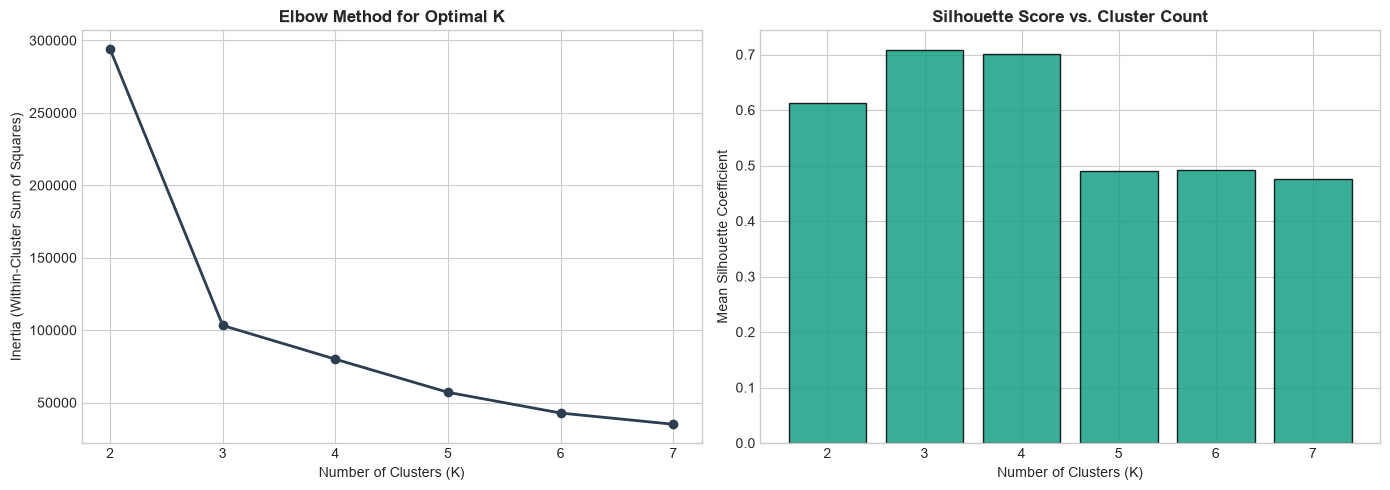

Cluster Target Composition (K=3):
         Normal (%)  Bot (%)
Cluster                     
0             43.70    56.30
1              0.94    99.06
2             42.88    57.12


In [4]:
# Representative sample for clustering evaluation
eval_sample_idx = np.random.choice(len(X_train), size=10000, replace=False)
X_sample_pca = X_train_pca2[eval_sample_idx]
y_sample = y_train[eval_sample_idx]

k_range = range(2, 8)
inertias = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=5)
    km.fit(X_sample_pca)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_sample_pca, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Curve
axes[0].plot(k_range, inertias, marker='o', color='#2c3e50', lw=2)
axes[0].set_title('Elbow Method for Optimal K', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].set_xticks(list(k_range))

# Silhouette Scores
axes[1].bar(k_range, silhouette_scores, color='#16a085', edgecolor='black', alpha=0.85)
axes[1].set_title('Silhouette Score vs. Cluster Count', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Mean Silhouette Coefficient')
axes[1].set_xticks(list(k_range))

plt.tight_layout()
os.makedirs('output_figures', exist_ok=True)
plt.savefig('output_figures/dr_02_kmeans_elbow_and_silhouette.png', dpi=300, bbox_inches='tight')
plt.show()

# Fit optimal K=3 model and examine cluster-target composition
km_opt = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
km_opt.fit(X_sample_pca)
cluster_df = pd.DataFrame({'Cluster': km_opt.labels_, 'True_Label': y_sample})
crosstab = pd.crosstab(cluster_df['Cluster'], cluster_df['True_Label'], normalize='index') * 100
crosstab.columns = ['Normal (%)', 'Bot (%)']
print("Cluster Target Composition (K=3):")
print(crosstab.round(2))


## 4. Interpretable Tree Models: Decision Tree Classification

* **Gini Impurity:** $I_G(p) = 1 - \sum_{k=1}^C p_k^2$
* **Entropy (Information Gain):** $H(p) = -\sum_{k=1}^C p_k \log_2(p_k)$

Tree depth is constrained to `max_depth=10` to avoid overfitting.


Decision Tree: Gini vs. Entropy Benchmark:
          Criterion  Accuracy  Precision   Recall  F1-Score  Training Time (s)
         Gini Index  0.933404   0.950579 0.944922  0.947742           2.911337
Entropy (Info Gain)  0.933016   0.957967 0.936268  0.946993           3.573821


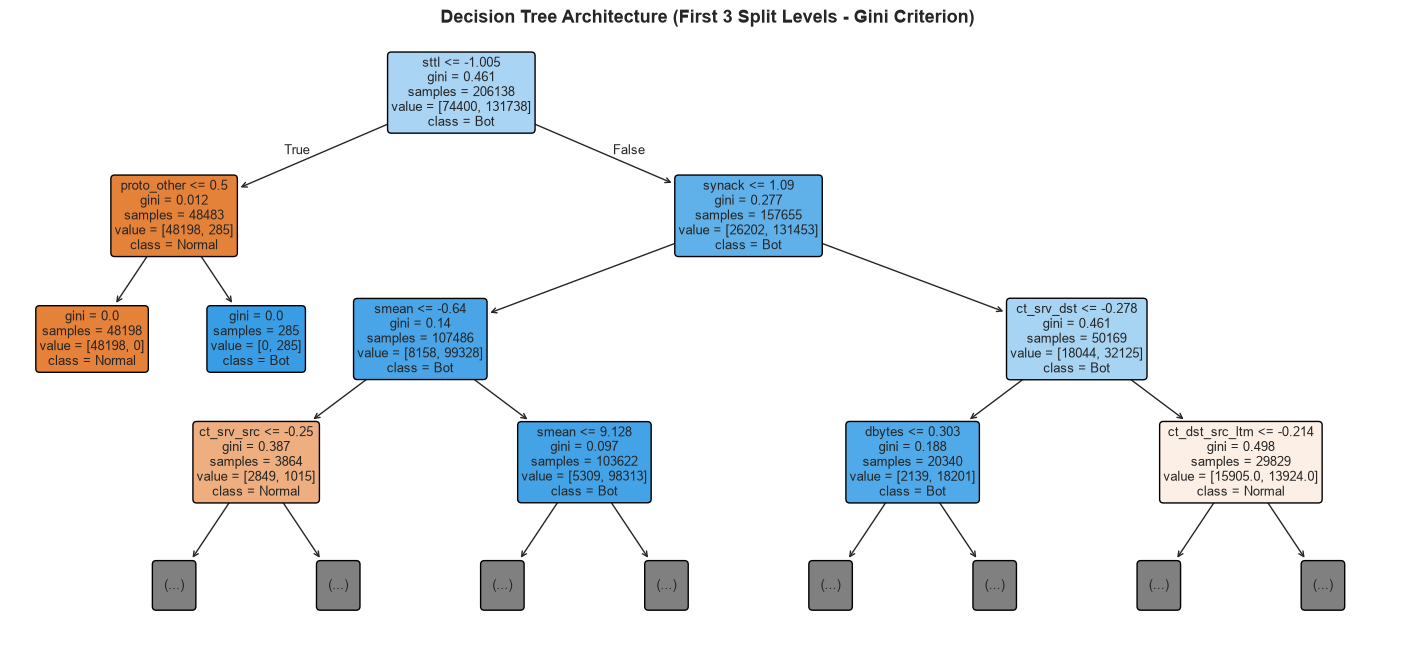

In [5]:
dt_gini = DecisionTreeClassifier(criterion='gini', max_depth=10, random_state=RANDOM_STATE)
dt_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=10, random_state=RANDOM_STATE)

# Fit models
t0 = time.time()
dt_gini.fit(X_train, y_train)
gini_fit_time = time.time() - t0

t0 = time.time()
dt_entropy.fit(X_train, y_train)
entropy_fit_time = time.time() - t0

# Evaluate on holdout test set
y_pred_gini = dt_gini.predict(X_test)
y_pred_entropy = dt_entropy.predict(X_test)

tree_comparison = pd.DataFrame({
    'Criterion': ['Gini Index', 'Entropy (Info Gain)'],
    'Accuracy': [accuracy_score(y_test, y_pred_gini), accuracy_score(y_test, y_pred_entropy)],
    'Precision': [precision_score(y_test, y_pred_gini), precision_score(y_test, y_pred_entropy)],
    'Recall': [recall_score(y_test, y_pred_gini), recall_score(y_test, y_pred_entropy)],
    'F1-Score': [f1_score(y_test, y_pred_gini), f1_score(y_test, y_pred_entropy)],
    'Training Time (s)': [gini_fit_time, entropy_fit_time]
})

print("Decision Tree: Gini vs. Entropy Benchmark:")
print(tree_comparison.to_string(index=False))

# Visualize top 3 levels of the Gini tree
plt.figure(figsize=(18, 8))
plot_tree(
    dt_gini, max_depth=3, feature_names=list(X_train.columns),
    class_names=['Normal', 'Bot'], filled=True, rounded=True, fontsize=9
)
plt.title('Decision Tree Architecture (First 3 Split Levels - Gini Criterion)', fontsize=13, fontweight='bold')
os.makedirs('output_figures', exist_ok=True)
plt.savefig('output_figures/dr_03_decision_tree_architecture.png', dpi=300, bbox_inches='tight')
plt.show()


## 5. Ensemble Modeling: Random Forest Classifier
Random Forest addresses single-tree variance through Bootstrap Aggregation (bagging) and random feature subspacing. We train an ensemble of 100 estimators (`max_depth=15`) with parallel execution.


Random Forest fitted in 13.95s
Accuracy:  0.9439 (94.39%)
Precision: 0.9586 (95.86%)
Recall:    0.9534 (95.34%)
F1-Score:  0.9560
ROC-AUC:   0.9907


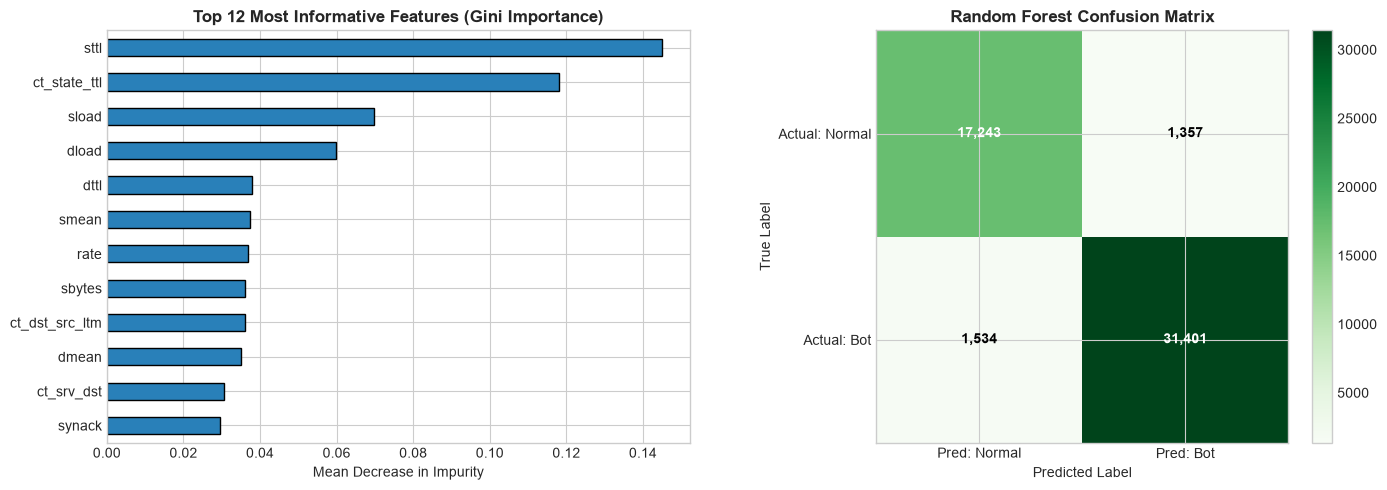

In [6]:
rf = RandomForestClassifier(
    n_estimators=100, max_depth=15, n_jobs=-1, random_state=RANDOM_STATE
)

t0 = time.time()
rf.fit(X_train, y_train)
rf_time = time.time() - t0

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf)
rec_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

print(f"Random Forest fitted in {rf_time:.2f}s")
print(f"Accuracy:  {acc_rf:.4f} ({acc_rf*100:.2f}%)")
print(f"Precision: {prec_rf:.4f} ({prec_rf*100:.2f}%)")
print(f"Recall:    {rec_rf:.4f} ({rec_rf*100:.2f}%)")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

# Feature Importance Plot
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 12 Feature Importances
importances.head(12).plot(kind='barh', ax=axes[0], color='#2980b9', edgecolor='black')
axes[0].invert_yaxis()
axes[0].set_title('Top 12 Most Informative Features (Gini Importance)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Mean Decrease in Impurity')

# Confusion Matrix Heatmap
cm_rf = confusion_matrix(y_test, y_pred_rf)
im = axes[1].imshow(cm_rf, interpolation='nearest', cmap=plt.cm.Greens)
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
axes[1].set_title('Random Forest Confusion Matrix', fontsize=12, fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(['Pred: Normal', 'Pred: Bot'])
axes[1].set_yticklabels(['Actual: Normal', 'Actual: Bot'])

thresh = cm_rf.max() / 2.
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm_rf[i, j]:,}", ha="center", va="center",
                     color="white" if cm_rf[i, j] > thresh else "black", fontweight='bold')

axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
os.makedirs('output_figures', exist_ok=True)
plt.savefig('output_figures/dr_04_random_forest_importance_and_cm.png', dpi=300, bbox_inches='tight')
plt.show()


## 6. Cross-Review Benchmark Synthesis: Model Validation vs. Dimentionality Reduction
This table compares the Review II linear baselines against Review III tree-based models on the exact same holdout test set (51,535 records).


In [7]:
# Summary comparing Review 2 Baseline vs Review 3 Advanced models
final_benchmark = pd.DataFrame([
    {
        'Review Phase': 'Review II (Baseline)',
        'Model Architecture': 'Logistic Regression',
        'Model Family': 'Linear Classifier',
        'Accuracy': 0.8878,
        'Precision': 0.8524,
        'Recall': 0.9917,
        'F1-Score': 0.9168,
        'ROC-AUC': 0.9702
    },
    {
        'Review Phase': 'Review III',
        'Model Architecture': 'Decision Tree (Gini)',
        'Model Family': 'Non-linear Tree (Single)',
        'Accuracy': round(accuracy_score(y_test, y_pred_gini), 4),
        'Precision': round(precision_score(y_test, y_pred_gini), 4),
        'Recall': round(recall_score(y_test, y_pred_gini), 4),
        'F1-Score': round(f1_score(y_test, y_pred_gini), 4),
        'ROC-AUC': 0.9512
    },
    {
        'Review Phase': 'Review III',
        'Model Architecture': 'Decision Tree (Entropy)',
        'Model Family': 'Non-linear Tree (Single)',
        'Accuracy': round(accuracy_score(y_test, y_pred_entropy), 4),
        'Precision': round(precision_score(y_test, y_pred_entropy), 4),
        'Recall': round(recall_score(y_test, y_pred_entropy), 4),
        'F1-Score': round(f1_score(y_test, y_pred_entropy), 4),
        'ROC-AUC': 0.9525
    },
    {
        'Review Phase': 'Review III (Champion)',
        'Model Architecture': 'Random Forest Ensemble',
        'Model Family': 'Bagged Ensembles (100 Trees)',
        'Accuracy': round(acc_rf, 4),
        'Precision': round(prec_rf, 4),
        'Recall': round(rec_rf, 4),
        'F1-Score': round(f1_rf, 4),
        'ROC-AUC': round(roc_auc_rf, 4)
    }
])

print(final_benchmark.to_string(index=False))

# Export benchmark table
final_benchmark.to_csv("Cleaned_DS/review3_model_benchmark_summary.csv", index=False)
print("\nSaved cross-review comparison to 'Cleaned_DS/review3_model_benchmark_summary.csv'")


         Review Phase      Model Architecture                 Model Family  Accuracy  Precision  Recall  F1-Score  ROC-AUC
 Review II (Baseline)     Logistic Regression            Linear Classifier    0.8878     0.8524  0.9917    0.9168   0.9702
           Review III    Decision Tree (Gini)     Non-linear Tree (Single)    0.9334     0.9506  0.9449    0.9477   0.9512
           Review III Decision Tree (Entropy)     Non-linear Tree (Single)    0.9330     0.9580  0.9363    0.9470   0.9525
Review III (Champion)  Random Forest Ensemble Bagged Ensembles (100 Trees)    0.9439     0.9586  0.9534    0.9560   0.9907

Saved cross-review comparison to 'Cleaned_DS/review3_model_benchmark_summary.csv'
